# FV 01 — EDGAR fundamentals and daily prices: coverage check

Protocol: [`discussions/Fair_Value/001`](../../discussions/Fair_Value/001_claude_fv01_data_plan.md). This is a data check, not a study: no signal or returns are computed.

It answers four questions before any DCF is built:
1. How many filers per year, and how many stop filing (delisted, acquired, deregistered)?
2. How complete are the facts a DCF needs, per year, and how often are values restated?
3. For how many CIKs, live and dead, do we have a price series that matches the period they filed in (Yahoo, Alpaca)?
4. Spot check on known delistings.

Run after `tools/edgar/edgar_download.py` and `tools/prices/daily_download.py` (both sources). 2026 is sealed: everything is cut at 2025-12-31.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parents[1] / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from equity_trading import edgar as E, daily_prices as P

OUT = Path("01"); OUT.mkdir(exist_ok=True)
AS_OF = pd.Timestamp("2025-12-31")
YEARS = range(2009, 2026)
e = E.edgar_dir()
print("EDGAR engine", E.EDGAR_VERSION, "| prices", P.DAILY_PRICES_VERSION, "|", e)
companies = pd.read_parquet(e / "companies.parquet")
filings = pd.read_parquet(e / "filings.parquet")
filings = filings[filings["filing_date"] <= AS_OF]
th = pd.read_parquet(e / "ticker_history.parquet")
status = E.company_status(filings, as_of=str(AS_OF.date()))
print(f"{len(companies):,} entities | {len(filings):,} filings kept | {len(status):,} CIKs with periodic reports")

EDGAR engine 0.1.2 | prices 0.1.1 | D:\MarketData\EDGAR
994,026 entities | 3,941,813 filings kept | 43,852 CIKs with periodic reports


## 1. Filers per year and exits

In [2]:
per = filings[filings["form"].isin(E.FACT_FORMS)].copy()
per["year"] = per["filing_date"].dt.year
base = per[per["form"].isin(["10-K", "10-Q"])]           # domestic periodic filers
filers = base.groupby("year")["cik"].nunique()
st = status.copy()
st["exit_year"] = np.where(st["active"], np.nan, st["last_periodic"].dt.year)
exits = st.loc[st["exit_year"].between(2009, 2025)].groupby("exit_year")["cik"].count()
dl = filings[filings["form"].isin(E.DELIST_FORMS)].assign(year=lambda x: x["filing_date"].dt.year)
dl_forms = dl.groupby(["year", "form"], observed=True)["cik"].nunique().unstack(fill_value=0)
t1 = pd.DataFrame({"filers_10K_10Q": filers, "stopped_filing": exits}).loc[2009:2025].fillna(0).astype(int)
t1 = t1.join(dl_forms.loc[2009:2025]).fillna(0).astype(int)
t1.to_csv(OUT / "filers_by_year.csv")
display(t1)
sic = companies.set_index("cik")["sic"]
print("SPAC / blank-check CIKs (SIC 6770) among periodic filers:", int(sic.reindex(status["cik"]).eq("6770").sum()))

,filers_10K_10Q,stopped_filing,15-12B,15-12G,15-15D,15F-12B,15F-12G,15F-15D,25,25-NSE
2009.0,9902,1257,195,568,393,14,27,8,197,347
2010.0,9300,1023,213,406,182,11,16,11,114,325
2011.0,8997,1069,198,430,134,10,14,10,109,294
2012.0,8563,978,193,450,161,5,15,5,106,331
2013.0,8245,879,235,368,148,4,17,3,99,264
2014.0,8162,838,199,306,146,13,10,15,79,208
2015.0,8020,934,252,306,169,8,7,13,66,216
2016.0,7561,829,263,284,188,12,8,9,85,259
2017.0,7283,741,252,279,182,6,8,3,93,224
2018.0,7063,665,255,264,175,7,2,2,94,194


SPAC / blank-check CIKs (SIC 6770) among periodic filers: 1707


## 2. DCF inputs: tag coverage and restatements

item,capex,cash,cfo,d_and_a,debt,equity,net_income,operating_income,revenue,shares
year,,,,,,,,,,
2009,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2010,0.05,0.06,0.06,0.05,0.04,0.05,0.06,0.05,0.05,0.06
2011,0.16,0.19,0.20,0.17,0.11,0.18,0.20,0.15,0.15,0.20
2012,0.61,0.78,0.86,0.67,0.32,0.78,0.83,0.62,0.57,0.86
2013,0.63,0.80,0.88,0.72,0.38,0.81,0.85,0.64,0.60,0.88
2014,0.63,0.81,0.88,0.73,0.39,0.81,0.86,0.65,0.61,0.89
2015,0.63,0.82,0.89,0.74,0.41,0.82,0.87,0.66,0.62,0.89
2016,0.64,0.82,0.89,0.75,0.42,0.82,0.87,0.67,0.62,0.88
2017,0.63,0.80,0.87,0.74,0.42,0.81,0.86,0.67,0.60,0.87


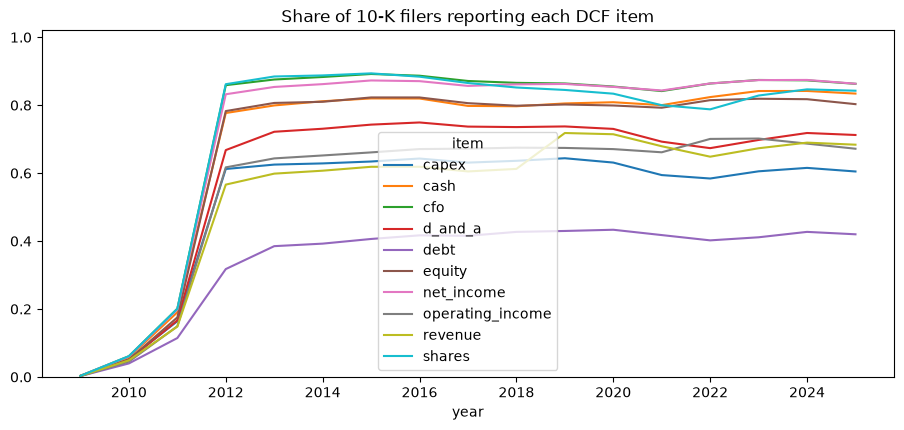

In [3]:
# Candidate tags per DCF item (first match wins in the panel builder, FV 02). Coverage = share of 10-K filers
# in the year whose 10-K reports at least one tag of the item.
ITEMS = {
    "revenue": ["Revenues", "RevenueFromContractWithCustomerExcludingAssessedTax", "SalesRevenueNet",
                "RevenueFromContractWithCustomerIncludingAssessedTax"],
    "operating_income": ["OperatingIncomeLoss"],
    "net_income": ["NetIncomeLoss", "ProfitLoss"],
    "cfo": ["NetCashProvidedByUsedInOperatingActivities",
            "NetCashProvidedByUsedInOperatingActivitiesContinuingOperations"],
    "capex": ["PaymentsToAcquirePropertyPlantAndEquipment", "PaymentsToAcquireProductiveAssets"],
    "d_and_a": ["DepreciationDepletionAndAmortization", "DepreciationAndAmortization", "Depreciation"],
    "cash": ["CashAndCashEquivalentsAtCarryingValue",
             "CashCashEquivalentsRestrictedCashAndRestrictedCashEquivalents"],
    "debt": ["LongTermDebt", "LongTermDebtNoncurrent", "DebtCurrent", "LongTermDebtCurrent"],
    "equity": ["StockholdersEquity"],
    "shares": ["EntityCommonStockSharesOutstanding", "CommonStockSharesOutstanding",
               "WeightedAverageNumberOfDilutedSharesOutstanding"],
}
tags = sorted({t for v in ITEMS.values() for t in v})
facts = E.load_facts(tags=tags, filed_max=str(AS_OF.date()))
facts = facts[facts["form"].astype(str) == "10-K"]
facts["year"] = facts["filed"].dt.year
tag2item = {t: k for k, v in ITEMS.items() for t in v}
facts["item"] = facts["tag"].astype(str).map(tag2item)
k10 = per[per["form"] == "10-K"].groupby("year")["cik"].nunique()
cov = (facts.groupby(["year", "item"])["cik"].nunique().unstack().div(k10, axis=0)).loc[2009:2025]
cov.round(3).to_csv(OUT / "item_coverage_10k.csv")
display(cov.round(2))
ax = cov.plot(figsize=(11, 4.5), title="Share of 10-K filers reporting each DCF item"); ax.set_ylim(0, 1.02)
plt.savefig(OUT / "item_coverage_10k.png", dpi=120, bbox_inches="tight"); plt.show()

In [4]:
# Restatements: same (cik, tag, unit, start, end) reported by more than one filing with a different value.
key = ["cik", "tag", "unit", "start", "end"]
g = facts.groupby(key, observed=True, dropna=False)["val"]
n_vals = g.nunique()
restated = (n_vals > 1).groupby(level="tag", observed=True).mean().sort_values(ascending=False)
print("share of facts later reported with a different value, by tag (10-K rows):")
display(restated.round(3).to_frame("restated_share"))
restated.to_csv(OUT / "restated_share.csv")

share of facts later reported with a different value, by tag (10-K rows):


,restated_share
tag,
OperatingIncomeLoss,0.108
NetCashProvidedByUsedInOperatingActivitiesContinuingOperations,0.107
DepreciationAndAmortization,0.084
NetCashProvidedByUsedInOperatingActivities,0.083
CommonStockSharesOutstanding,0.083
Revenues,0.082
Depreciation,0.082
SalesRevenueNet,0.082
DepreciationDepletionAndAmortization,0.078


## 3. Price series per CIK: Yahoo and Alpaca

In [5]:
# Window each CIK filed periodic reports, clipped to 2009-2025; a price source 'matches' a CIK if one of its
# symbol candidates has data covering >= 80% of that window. Price data starting well after the window
# begins (> 1 year) is flagged 'late': usually a reused symbol (a different company today).
win = status.assign(w0=status["first_periodic"].clip(lower=pd.Timestamp("2009-01-01")),
                    w1=status["last_periodic"].clip(upper=AS_OF))
win = win[win["w1"] > win["w0"]]
ycov = P.yahoo_coverage().assign(first=lambda x: pd.to_datetime(x["first"]), last=lambda x: pd.to_datetime(x["last"]))
ycov = ycov.set_index("symbol")
th["yahoo"] = th["symbol"].map(E.yahoo_symbol)
th["alpaca"] = th["symbol"].str.replace("-", ".", regex=False)

def classify(src_first, src_last, w0, w1, floor=None):
    if floor is not None:
        w0 = max(w0, floor)
        if w1 <= w0:
            return "out_of_range"
    if pd.isna(src_first):
        return "missing"
    overlap = (min(src_last, w1) - max(src_first, w0)).days
    if overlap >= 0.8 * (w1 - w0).days:
        return "match"
    if src_first > w0 + pd.Timedelta(days=365):
        return "late"
    return "partial"

RANK = {"match": 0, "partial": 1, "late": 2, "missing": 3, "out_of_range": 4}
alp = P.alpaca_coverage(sorted(th["alpaca"].unique())).set_index("symbol")
rows = []
for cik, w in win.set_index("cik")[["w0", "w1", "active"]].iterrows():
    cands = th[th["cik"] == cik] if cik in th["cik"].values else th.iloc[:0]
    best_y, best_a = "missing", "missing"
    for _, c in cands.iterrows():
        y = ycov.loc[c["yahoo"]] if c["yahoo"] in ycov.index else None
        ry = classify(y["first"] if y is not None and y["status"] == "ok" else pd.NaT,
                      y["last"] if y is not None else pd.NaT, w["w0"], w["w1"])
        best_y = min(best_y, ry, key=RANK.get)
        a = alp.loc[c["alpaca"]] if c["alpaca"] in alp.index else None
        ra = classify(pd.to_datetime(a["first"]).tz_localize(None) if a is not None and a["rows"] else pd.NaT,
                      pd.to_datetime(a["last"]).tz_localize(None) if a is not None and a["rows"] else pd.NaT,
                      w["w0"], w["w1"], floor=pd.Timestamp("2016-01-01"))
        best_a = min(best_a, ra, key=RANK.get)
    rows.append({"cik": cik, "active": w["active"], "has_symbol": len(cands) > 0, "yahoo": best_y, "alpaca": best_a})
pm = pd.DataFrame(rows)
pm.to_parquet(OUT / "price_match.parquet", index=False)
for src in ["yahoo", "alpaca"]:
    t = pd.crosstab(pm["active"].map({True: "active", False: "dead"}), pm[src], normalize="index").round(3)
    print(src); display(t)
print("CIKs without any symbol candidate:", f"{(~pm['has_symbol']).mean():.1%}",
      "| dead:", f"{(~pm.loc[~pm['active'], 'has_symbol']).mean():.1%}")

yahoo


yahoo,late,match,missing,partial
active,,,,
active,0.056,0.707,0.232,0.004
dead,0.066,0.096,0.833,0.005


alpaca


alpaca,late,match,missing,partial
active,,,,
active,0.042,0.692,0.241,0.025
dead,0.020,0.208,0.748,0.024


CIKs without any symbol candidate: 26.1% | dead: 34.3%


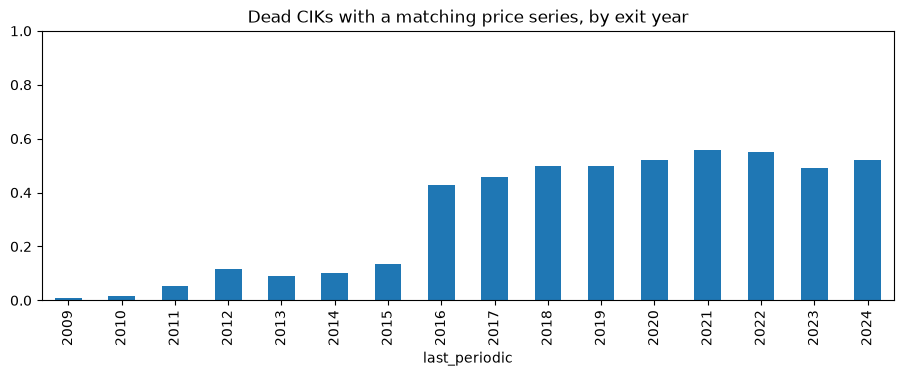

active CIKs matched: 78.2% | dead CIKs matched: 27.9%


In [6]:
# Combined: a dead CIK is usable if either source matches (Yahoo first, else Alpaca for 2016+).
pm["any_match"] = (pm["yahoo"] == "match") | (pm["alpaca"] == "match")
dead = pm[~pm["active"]].merge(status[["cik", "last_periodic"]], on="cik")
by_year = dead.groupby(dead["last_periodic"].dt.year)["any_match"].agg(["mean", "count"]).loc[2009:2025]
by_year.round(3).to_csv(OUT / "dead_cik_price_match_by_exit_year.csv")
ax = by_year["mean"].plot(kind="bar", figsize=(11, 3.5), title="Dead CIKs with a matching price series, by exit year")
ax.set_ylim(0, 1); plt.savefig(OUT / "dead_match_by_year.png", dpi=120, bbox_inches="tight"); plt.show()
print(f"active CIKs matched: {pm.loc[pm['active'], 'any_match'].mean():.1%} | dead CIKs matched: {dead['any_match'].mean():.1%}")

## 4. Spot check: known delistings

In [7]:
SPOT = {"SIVB": "SVB Financial (failed 2023)", "FRC": "First Republic (failed 2023)",
        "BBBY": "Bed Bath & Beyond (bankrupt 2023)", "ATVI": "Activision (acquired 2023)",
        "TWTR": "Twitter (taken private 2022)", "CELG": "Celgene (acquired 2019)",
        "AAPL": "Apple (live control)"}

def span(first, last):
    return f"{pd.Timestamp(first):%Y-%m-%d}..{pd.Timestamp(last):%Y-%m-%d}"

rows = []
for s, desc in SPOT.items():
    y = ycov.loc[s] if s in ycov.index else None
    a = alp.loc[s] if s in alp.index else None
    rows.append({"symbol": s, "what": desc,
                 "edgar_ciks": th.loc[th["symbol"] == s, "cik"].unique().tolist(),
                 "yahoo": "not requested" if y is None else (span(y["first"], y["last"]) if y["status"] == "ok" else y["status"]),
                 "alpaca": "none" if a is None or not a["rows"] else span(a["first"], a["last"])})
spot = pd.DataFrame(rows); spot.to_csv(OUT / "spot_check.csv", index=False); display(spot)

,symbol,what,edgar_ciks,yahoo,alpaca
0,SIVB,SVB Financial (failed 2023),[719739],missing,2016-01-04..2023-03-09
1,FRC,First Republic (failed 2023),[1420239],missing,2016-01-04..2023-04-28
2,BBBY,Bed Bath & Beyond (bankrupt 2023),"[886158, 1130713]",missing,2016-01-04..2025-12-31
3,ATVI,Activision (acquired 2023),[718877],missing,2016-01-04..2023-10-13
4,TWTR,Twitter (taken private 2022),[1418091],missing,2016-01-04..2022-10-27
5,CELG,Celgene (acquired 2019),[816284],missing,2016-01-04..2019-11-20
6,AAPL,Apple (live control),[320193],2008-01-02..2025-12-31,2016-01-04..2025-12-31


## Readout (fill in after the run)

- Filers per year / exits per year:
- DCF item coverage (weakest items):
- Restatement share:
- Price match, active vs dead, Yahoo vs Alpaca; dead-CIK match by exit year:
- Decision for FV 02 (panel builder): which delisted CIKs are usable, and whether the 2009–2015 dead firms need another price source.